In [18]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv


In [19]:
load_dotenv()
model = ChatGroq(model="openai/gpt-oss-20b")

In [20]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [21]:
def create_outline(state: BlogState)-> BlogState:
    title = state['title']
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content
    state['outline'] = outline
    return state

In [22]:
def create_blog(state: BlogState)-> BlogState:
    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the following outline \n {outline}'

    content = model.invoke(prompt).content

    state['content']= content
    return state

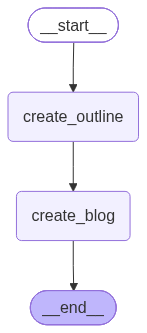

In [23]:
graph = StateGraph(BlogState)

graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_outline',END)
workflow = graph.compile()
workflow


In [24]:
initial_state = {'title': 'Rise of AI in India'}
final_state = workflow.invoke(initial_state)
print(final_state)


{'title': 'Rise of AI in India', 'outline': '**Blog Outline: “Rise of AI in India”**\n\n---\n\n### 1. Introduction  \n- **Hook**: A striking statistic or anecdote (e.g., “India’s AI market is projected to hit $10\u202fbillion by 2025.”)  \n- **Purpose**: Explain why the rise of AI matters to India’s economy, society, and global standing.  \n- **Scope**: Briefly outline what the post will cover (policy, industry, academia, challenges, future).  \n\n---\n\n### 2. Historical Context  \n- **Early AI Research in India**  \n  - 1970s–1990s: AI labs at IITs, CSIR, and BARC.  \n  - Pioneering projects (e.g., Indian Language Processing, early machine translation).  \n- **Shift to Commercialization**  \n  - 2000s: IT boom, emergence of AI startups.  \n  - 2010s: Cloud adoption, data explosion.  \n\n---\n\n### 3. Current Landscape of AI in India  \n- **Market Size & Growth**  \n  - CAGR, projected market value, comparison with global peers.  \n- **Key Sectors Leveraging AI**  \n  - **Healthcare**

In [25]:
print(final_state['outline'])

**Blog Outline: “Rise of AI in India”**

---

### 1. Introduction  
- **Hook**: A striking statistic or anecdote (e.g., “India’s AI market is projected to hit $10 billion by 2025.”)  
- **Purpose**: Explain why the rise of AI matters to India’s economy, society, and global standing.  
- **Scope**: Briefly outline what the post will cover (policy, industry, academia, challenges, future).  

---

### 2. Historical Context  
- **Early AI Research in India**  
  - 1970s–1990s: AI labs at IITs, CSIR, and BARC.  
  - Pioneering projects (e.g., Indian Language Processing, early machine translation).  
- **Shift to Commercialization**  
  - 2000s: IT boom, emergence of AI startups.  
  - 2010s: Cloud adoption, data explosion.  

---

### 3. Current Landscape of AI in India  
- **Market Size & Growth**  
  - CAGR, projected market value, comparison with global peers.  
- **Key Sectors Leveraging AI**  
  - **Healthcare**: Diagnostics, telemedicine.  
  - **Finance**: Fraud detection, credit sco

In [26]:
print(final_state['content'])

# Rise of AI in India  
*A Deep Dive into the Technology That’s Shaping the Nation’s Future*  

---

## 1. Introduction  

> **Hook** – *“India’s AI market is projected to hit $10 billion by 2025, up from just $1.2 billion in 2019.”*  

The numbers speak for themselves: the AI sector is no longer a niche research curiosity; it’s a strategic engine that will drive India’s GDP, job creation, and global influence. AI is already transforming everyday life—from the way doctors diagnose disease to how farmers decide what to plant. The stakes are high: a robust AI ecosystem will determine whether India can keep pace with tech giants, close the digital divide, and tackle pressing social challenges.

**Purpose** – This post explains why the rise of AI matters: it fuels economic diversification, unlocks new health and agriculture solutions, and positions India as a key player in the global AI race.

**Scope** – We’ll walk through the historical roots, the current market, the policy landscape, th